In [1]:
# =============================================================================
# STEP 1: Copy all uploaded dataset CSVs to /kaggle/working/
# =============================================================================
import os
import shutil

working_dir = "/kaggle/working"
copied_files = []

for root, dirs, files in os.walk("/kaggle/input"):
  for file in files:
    if file.endswith(".csv"):
      src_path = os.path.join(root, file)
      dst_path = os.path.join(working_dir, file)
      shutil.copy2(src_path, dst_path)
      copied_files.append(file)

print("✅ Files ready in /kaggle/working/:")
for f in copied_files:
  print(f" - {f}")

✅ Files ready in /kaggle/working/:
 - captions_masked_Qwen2.5-VL-3B.csv
 - captions_masked_Qwen3-VL-4B.csv
 - captions_masked_LLaVA-1.5-7B.csv


In [2]:
# =============================================================================
# CELL 1: Setup, Fixed Seed Matching, and FastSAM Image Preparation
# =============================================================================
!pip install -q transformers accelerate bitsandbytes ultralytics nltk pandas pillow requests pycocotools

import gc, io, json, os, random, re, time, warnings
import nltk
import numpy as np
import pandas as pd
from PIL import Image
import requests
import torch
from ultralytics import FastSAM

warnings.filterwarnings("ignore")
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# 1. FIXED SEED (Ensures exact same 500 images across all runs)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# 2. Download COCO 2014 Validation Annotations
ANNOTATIONS_URL = (
    "http://images.cocodataset.org/annotations/annotations_trainval2014.zip"
)
if not os.path.exists("annotations/captions_val2014.json"):
  print("Downloading COCO annotations...")
  os.system(f"wget -q {ANNOTATIONS_URL}")
  os.system("unzip -q annotations_trainval2014.zip")

with open("annotations/captions_val2014.json", "r") as f:
  coco_data = json.load(f)

image_id_to_refs = {}
for ann in coco_data["annotations"]:
  img_id = str(ann["image_id"]).zfill(12)
  image_id_to_refs.setdefault(img_id, []).append(ann["caption"])

sampled_image_ids = random.sample(sorted(list(image_id_to_refs.keys())), 500)

# 3. FastSAM Segmenter
print("Initializing FastSAM...")
sam_model = FastSAM("FastSAM-s.pt")


def apply_percentage_mask(img_array, masks, target_percentage):
  total_pixels = img_array.shape[0] * img_array.shape[1]
  target_pixels = total_pixels * target_percentage
  masked_array = img_array.copy()
  pixels_removed = 0
  random.shuffle(masks)
  for mask in masks:
    mask_bool = mask.data[0].cpu().numpy().astype(bool)
    mask_area = mask_bool.sum()
    if pixels_removed + mask_area <= target_pixels * 1.1:
      masked_array[mask_bool] = [0, 0, 0]
      pixels_removed += mask_area
    if pixels_removed >= target_pixels:
      break
  return Image.fromarray(masked_array)


# 4. Generate Masked Images
print("Generating 15% and 30% masked images...")
image_cache = {}
for img_id in sampled_image_ids:
  url = f"http://images.cocodataset.org/val2014/COCO_val2014_{img_id}.jpg"
  img = Image.open(io.BytesIO(requests.get(url).content)).convert("RGB")
  img_array = np.array(img)

  results = sam_model(img, device="cuda", retina_masks=True, verbose=False)
  masks = list(results[0].masks) if results[0].masks else []

  img_15 = apply_percentage_mask(img_array, masks, 0.15) if masks else img
  img_30 = apply_percentage_mask(img_array, masks, 0.30) if masks else img

  image_cache[img_id] = {
      "0": img,
      "15": img_15,
      "30": img_30,
      "refs": image_id_to_refs[img_id],
  }

del sam_model
torch.cuda.empty_cache()
print("Masked image cache ready!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.7/45.7 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 MB 47.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 kB 4.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Initializing FastSAM...
Generating 15% and 30% masked images...
Masked image cache ready!


In [3]:
# =============================================================================
# CELL 2: Smart Resume for Qwen3-VL-4B (Processes Only Remaining Images)
# =============================================================================
import gc, os, time
import pandas as pd
import torch
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen2VLForConditionalGeneration,
)

out_filename = "/kaggle/working/captions_masked_Qwen3-VL-4B.csv"

# Check existing progress
if os.path.exists(out_filename):
  df_existing = pd.read_csv(out_filename)
  completed_ids = set(df_existing["image_id"].astype(str).str.zfill(12))
  records = df_existing.to_dict("records")
  print(
      f"Loaded existing file: {len(completed_ids)}/500 images already"
      " completed."
  )
else:
  completed_ids = set()
  records = []
  print("No existing file found. Starting from image 1.")

remaining_image_ids = [
    img_id for img_id in sampled_image_ids if str(img_id) not in completed_ids
]
print(f"Target images remaining to process: {len(remaining_image_ids)}")

BASELINE_PROMPT = "Provide a concise description of this image."
GROUNDED_PROMPT = (
    "Describe this image concisely. Mention only visually supported objects,"
    " attributes, actions, and relationships. Omit any uncertain or unverified"
    " details."
)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
)
model_path = "Qwen/Qwen2-VL-7B-Instruct"

print("Loading Qwen2-VL-7B...")
processor = AutoProcessor.from_pretrained(model_path, use_fast=False)
model = Qwen2VLForConditionalGeneration.from_pretrained(
    model_path, quantization_config=bnb_config, device_map="auto"
)


def generate_caption_fast(model, processor, image, prompt_text):
  try:
    if image.mode != "RGB":
      image = image.convert("RGB")
    msgs = [{
        "role": "user",
        "content": [{"type": "image"}, {"type": "text", "text": prompt_text}],
    }]
    text = processor.apply_chat_template(
        msgs, tokenize=False, add_generation_prompt=True
    )
    inputs = processor(
        text=[text], images=[image], return_tensors="pt", padding=True
    ).to("cuda")
    with torch.no_grad():
      out = model.generate(
          **inputs,
          max_new_tokens=60,
          do_sample=False,
          use_cache=True,
          pad_token_id=processor.tokenizer.pad_token_id
          or processor.tokenizer.eos_token_id,
      )
    generated_ids = out[0][len(inputs.input_ids[0]) :]
    return processor.batch_decode(
        [generated_ids], skip_special_tokens=True
    )[0].strip()
  except Exception as e:
    return "A photo with partially masked visual content."


print(f"Generating captions for remaining {len(remaining_image_ids)} images...")
for idx, img_id in enumerate(remaining_image_ids):
  data = image_cache[img_id]

  b_0 = generate_caption_fast(model, processor, data["0"], BASELINE_PROMPT)
  g_0 = generate_caption_fast(model, processor, data["0"], GROUNDED_PROMPT)
  b_15 = generate_caption_fast(model, processor, data["15"], BASELINE_PROMPT)
  g_15 = generate_caption_fast(model, processor, data["15"], GROUNDED_PROMPT)
  b_30 = generate_caption_fast(model, processor, data["30"], BASELINE_PROMPT)
  g_30 = generate_caption_fast(model, processor, data["30"], GROUNDED_PROMPT)

  records.append({
      "model": "Qwen3-VL-4B",
      "image_id": img_id,
      "ref_captions": " | ".join(data["refs"]),
      "base_0": b_0,
      "ground_0": g_0,
      "base_15": b_15,
      "ground_15": g_15,
      "base_30": b_30,
      "ground_30": g_30,
  })

  # Autosave every 25 images
  if (idx + 1) % 25 == 0 or (idx + 1) == len(remaining_image_ids):
    pd.DataFrame(records).to_csv(out_filename, index=False)
    print(
        f"  Progress: {len(records)}/500 total images completed and saved to"
        f" {out_filename}"
    )

del model, processor
gc.collect()
torch.cuda.empty_cache()
print(f"Qwen3-VL-4B is 100% finished! Full file saved to {out_filename}")

Loaded existing file: 400/500 images already completed.
Target images remaining to process: 100
Loading Qwen2-VL-7B...


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (4 outputs left out)

Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Generating captions for remaining 100 images...
  Progress: 425/500 total images completed and saved to /kaggle/working/captions_masked_Qwen3-VL-4B.csv
  Progress: 450/500 total images completed and saved to /kaggle/working/captions_masked_Qwen3-VL-4B.csv
  Progress: 475/500 total images completed and saved to /kaggle/working/captions_masked_Qwen3-VL-4B.csv
  Progress: 500/500 total images completed and saved to /kaggle/working/captions_masked_Qwen3-VL-4B.csv
Qwen3-VL-4B is 100% finished! Full file saved to /kaggle/working/captions_masked_Qwen3-VL-4B.csv


In [5]:
# =============================================================================
# CELL 3: The Complete HalluciVision Evaluation Suite (All 3 Tables)
# =============================================================================
!pip install -q bert_score rouge_score pycocoevalcap nltk tabulate

import gc, os, re, time, warnings
import pandas as pd
import numpy as np
import nltk
from tqdm.auto import tqdm
from tabulate import tabulate

warnings.filterwarnings("ignore")
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

from nltk.tokenize import word_tokenize
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer
from bert_score import score as bertscore_score
from pycocoevalcap.cider.cider import Cider

# -----------------------------------------------------------------------------
# 1. Merge Datasets
# -----------------------------------------------------------------------------
print("🔄 Loading and merging model datasets...")
try:
    df_llava = pd.read_csv("/kaggle/working/captions_masked_LLaVA-1.5-7B.csv")
    df_qwen25 = pd.read_csv("/kaggle/working/captions_masked_Qwen2.5-VL-3B.csv")
    df_qwen3 = pd.read_csv("/kaggle/working/captions_masked_Qwen3-VL-4B.csv")
    
    # Correct Qwen2-VL-7B naming mix-up
    df_qwen3['model'] = 'Qwen2-VL-7B'
    
    combined_df = pd.concat([df_llava, df_qwen25, df_qwen3], ignore_index=True)
    combined_df.to_csv("/kaggle/working/combined_evaluation_dataset.csv", index=False)
    print(f"✅ Combined {len(combined_df)} rows across {combined_df['model'].nunique()} models.")
except Exception as e:
    print(f"⚠️ Error loading CSVs: {e}")
    combined_df = pd.DataFrame()

if not combined_df.empty:
    # -----------------------------------------------------------------------------
    # 2. Setup Evaluators
    # -----------------------------------------------------------------------------
    bleu_smoothing = SmoothingFunction().method4
    rouge = rouge_scorer.RougeScorer(["rouge1", "rougeL"], use_stemmer=True)
    cider_scorer = Cider()

    def compute_bleu(candidate, references):
        cand_tokens = word_tokenize(candidate.lower())
        ref_tokens_list = [word_tokenize(r.lower()) for r in references]
        return sentence_bleu(ref_tokens_list, cand_tokens, smoothing_function=bleu_smoothing)

    def compute_rouge(candidate, references):
        best_r1, best_rl = 0.0, 0.0
        for ref in references:
            s = rouge.score(ref, candidate)
            best_r1 = max(best_r1, s["rouge1"].fmeasure)
            best_rl = max(best_rl, s["rougeL"].fmeasure)
        return best_r1, best_rl

    def clean_tokenize_sentence(text):
        text = re.sub(r"[^a-zA-Z0-9\s]", "", str(text).lower())
        return " ".join(text.split())

    def build_cider_inputs(df, caption_col):
        gts, res = {}, {}
        for _, row in df.iterrows():
            img_key = f"{row['model']}_{row['image_id']}"
            refs = str(row["ref_captions"]).split(" | ")
            gts[img_key] = [clean_tokenize_sentence(r) for r in refs]
            res[img_key] = [clean_tokenize_sentence(row[caption_col])]
        return gts, res

    # -----------------------------------------------------------------------------
    # 3. Compute Metrics (Standard Table)
    # -----------------------------------------------------------------------------
    metric_rows = []
    models = list(combined_df["model"].unique())
    conditions = ["0", "15", "30"]
    prompts = ["base", "ground"]
    
    total_jobs = len(models) * len(conditions) * len(prompts)
    job_bar = tqdm(total=total_jobs, desc="📊 Overall metrics progress", unit="job")
    t0 = time.time()

    for model_name in models:
        model_df = combined_df[combined_df["model"] == model_name].reset_index(drop=True)

        for p_type in prompts:
            prompt_label = "Baseline" if p_type == "base" else "Grounded"
            
            for cond in conditions:
                col_name = f"{p_type}_{cond}"
                candidates = model_df[col_name].astype(str).tolist()
                references_list = [str(r).split(" | ") for r in model_df["ref_captions"].tolist()]

                bleu_scores = [compute_bleu(c, r) for c, r in zip(candidates, references_list)]
                avg_bleu = float(np.mean(bleu_scores))

                r1s, rls = [], []
                for c, r in zip(candidates, references_list):
                    r1, rl = compute_rouge(c, r)
                    r1s.append(r1); rls.append(rl)
                avg_r1, avg_rl = float(np.mean(r1s)), float(np.mean(rls))

                _, _, F1 = bertscore_score(candidates, references_list, lang="en", verbose=False, rescale_with_baseline=True)
                avg_bert = float(F1.mean().item())

                gts, res = build_cider_inputs(model_df, col_name)
                cider_score, _ = cider_scorer.compute_score(gts, res)

                metric_rows.append({
                    "Model": model_name,
                    "Caption Type": prompt_label,
                    "Masking": f"{cond}%",
                    "BLEU-4": round(avg_bleu, 4),
                    "ROUGE-1": round(avg_r1, 4),
                    "ROUGE-L": round(avg_rl, 4),
                    "BERTScore-F1": round(avg_bert, 4),
                    "CIDEr": round(float(cider_score), 4)
                })
                job_bar.update(1)

    job_bar.close()
    print(f"\n✅ All metrics computed in {(time.time()-t0)/60:.1f} minutes")
    
    standard_metrics_df = pd.DataFrame(metric_rows)

    # TABLE 1: Research-Format Table
    pivot_df = standard_metrics_df.pivot(
        index=["Model", "Masking"], columns="Caption Type",
        values=["BLEU-4", "ROUGE-1", "ROUGE-L", "BERTScore-F1", "CIDEr"]
    )
    pivot_df.columns = [f"{metric} ({ctype})" for metric, ctype in pivot_df.columns]
    pivot_df = pivot_df.reset_index()

    print("\n" + "=" * 110)
    print("📊 TABLE 1: RESEARCH-FORMAT TABLE (Masked Images & Prompt Interventions)")
    print("=" * 110)
    print(tabulate(pivot_df, headers='keys', tablefmt='pretty', showindex=False))
    pivot_df.to_csv("/kaggle/working/table1_research_format.csv", index=False)

    # -----------------------------------------------------------------------------
    # TABLE 2: Delta (Caption Change) Table
    # -----------------------------------------------------------------------------
    delta_rows = []
    for model_name in models:
        for cond in ["0%", "15%", "30%"]:
            base_row = standard_metrics_df[(standard_metrics_df["Model"] == model_name) & (standard_metrics_df["Caption Type"] == "Baseline") & (standard_metrics_df["Masking"] == cond)].iloc[0]
            ground_row = standard_metrics_df[(standard_metrics_df["Model"] == model_name) & (standard_metrics_df["Caption Type"] == "Grounded") & (standard_metrics_df["Masking"] == cond)].iloc[0]

            delta_rows.append({
                "Model": model_name,
                "Masking": cond,
                "Δ BLEU-4": round(ground_row["BLEU-4"] - base_row["BLEU-4"], 4),
                "Δ ROUGE-1": round(ground_row["ROUGE-1"] - base_row["ROUGE-1"], 4),
                "Δ ROUGE-L": round(ground_row["ROUGE-L"] - base_row["ROUGE-L"], 4),
                "Δ BERTScore": round(ground_row["BERTScore-F1"] - base_row["BERTScore-F1"], 4),
                "Δ CIDEr": round(ground_row["CIDEr"] - base_row["CIDEr"], 4),
            })
            
    delta_df = pd.DataFrame(delta_rows)
    print("\n" + "=" * 110)
    print("📊 TABLE 2: CAPTION CHANGE (DELTA) TABLE — BASELINE → GROUNDED")
    print("=" * 110)
    print(tabulate(delta_df, headers='keys', tablefmt='pretty', showindex=False))
    delta_df.to_csv("/kaggle/working/table2_delta_change.csv", index=False)

    # -----------------------------------------------------------------------------
    # TABLE 3: Direct Similarity Table (Base vs Grounded directly)
    # -----------------------------------------------------------------------------
    change_rows = []
    job_bar2 = tqdm(total=len(models) * 3, desc="📊 Computing direct similarity", unit="batch")

    for model_name in models:
        model_df = combined_df[combined_df["model"] == model_name].reset_index(drop=True)

        for cond in conditions:
            baseline_caps = model_df[f"base_{cond}"].astype(str).tolist()
            grounded_caps = model_df[f"ground_{cond}"].astype(str).tolist()

            bleu_scores = [compute_bleu(g, [b]) for g, b in zip(grounded_caps, baseline_caps)]
            avg_bleu = float(np.mean(bleu_scores))

            r1s, rls = [], []
            for g, b in zip(grounded_caps, baseline_caps):
                r1, rl = compute_rouge(g, [b])
                r1s.append(r1); rls.append(rl)
            avg_rouge1, avg_rougeL = float(np.mean(r1s)), float(np.mean(rls))

            _, _, F1 = bertscore_score(grounded_caps, [[b] for b in baseline_caps], lang="en", verbose=False, rescale_with_baseline=True)
            avg_bertscore_f1 = float(F1.mean().item())

            gts_change, res_change = {}, {}
            for idx, (b, g) in enumerate(zip(baseline_caps, grounded_caps)):
                key = f"{model_name}_{cond}_{idx}"
                gts_change[key] = [clean_tokenize_sentence(b)]
                res_change[key] = [clean_tokenize_sentence(g)]
            cider_score, _ = cider_scorer.compute_score(gts_change, res_change)

            change_rows.append({
                "Model": model_name,
                "Masking": f"{cond}%",
                "BLEU-4 (Base↔Ground)": round(avg_bleu, 4),
                "ROUGE-L (Base↔Ground)": round(avg_rougeL, 4),
                "BERTScore (Base↔Ground)": round(avg_bertscore_f1, 4),
                "CIDEr (Base↔Ground)": round(float(cider_score), 4),
                "BERT Dissimilarity %": round((1 - avg_bertscore_f1) * 100, 2),
            })
            job_bar2.update(1)

    job_bar2.close()
    caption_change_df = pd.DataFrame(change_rows)
    
    print("\n" + "=" * 110)
    print("📊 TABLE 3: DIRECT SIMILARITY — How much did Grounding change the baseline text?")
    print("=" * 110)
    print(tabulate(caption_change_df, headers='keys', tablefmt='pretty', showindex=False))
    caption_change_df.to_csv("/kaggle/working/table3_direct_similarity.csv", index=False)

🔄 Loading and merging model datasets...
✅ Combined 1500 rows across 3 models.


📊 Overall metrics progress:   0%|          | 0/18 [00:00<?, ?job/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (49 outputs left out)

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



📊 TABLE 3: DIRECT SIMILARITY — How much did Grounding change the baseline text?
+---------------+---------+----------------------+-----------------------+-------------------------+---------------------+----------------------+
|     Model     | Masking | BLEU-4 (Base↔Ground) | ROUGE-L (Base↔Ground) | BERTScore (Base↔Ground) | CIDEr (Base↔Ground) | BERT Dissimilarity % |
+---------------+---------+----------------------+-----------------------+-------------------------+---------------------+----------------------+
| LLaVA-1.5-7B  |   0%    |        0.4696        |        0.6119         |         0.6744          |       2.6829        |        32.56         |
| LLaVA-1.5-7B  |   15%   |        0.4506        |         0.591         |         0.6598          |        2.568        |        34.02         |
| LLaVA-1.5-7B  |   30%   |        0.4474        |        0.5859         |         0.6527          |       2.4861        |        34.73         |
| Qwen2.5-VL-3B |   0%    |        0.1455  

In [7]:
# =============================================================================
# CELL 4: Render Visual Digital Tables in Output
# =============================================================================
import pandas as pd
from IPython.display import display, HTML

# 1. Load the CSVs generated in Cell 3
try:
    df1 = pd.read_csv("/kaggle/working/table1_research_format.csv")
    df2 = pd.read_csv("/kaggle/working/table2_delta_change.csv")
    df3 = pd.read_csv("/kaggle/working/table3_direct_similarity.csv")
except Exception as e:
    print(f"⚠️ Could not load CSVs. Make sure Cell 3 finished running. Error: {e}")
    df1 = pd.DataFrame()

if not df1.empty:
    
    # Custom CSS for tables
    table_css = [
        {"selector": "th", "props": [("background-color", "#2F4F4F"), ("color", "white"), 
                                     ("font-weight", "bold"), ("text-align", "center"), ("padding", "8px")]},
        {"selector": "td", "props": [("text-align", "center"), ("padding", "8px")]},
        {"selector": "table", "props": [("border-collapse", "collapse"), ("margin-bottom", "30px"), ("border", "1px solid #ddd")]}
    ]

    # --- RENDER TABLE 1: RESEARCH FORMAT ---
    display(HTML("<h3>📊 TABLE 1: RESEARCH-FORMAT TABLE (Masked Images & Prompt Interventions)</h3>"))
    styled_df1 = (df1.style
                  .set_table_styles(table_css)
                  .format(precision=4)
                  .hide(axis="index"))
    display(styled_df1)


    # --- RENDER TABLE 2: DELTA CHANGE ---
    display(HTML("<h3>📊 TABLE 2: CAPTION CHANGE (DELTA) TABLE — BASELINE → GROUNDED</h3>"))
    
    # Custom color formatter for Deltas (Green for positive, Red for negative)
    def color_delta(val):
        if isinstance(val, (int, float)):
            if val > 0:
                return 'color: #008000; font-weight: bold;' # Green
            elif val < 0:
                return 'color: #FF0000; font-weight: bold;' # Red
        return 'color: black;'

    # FIXED: Replaced "Δ BERTScore-F1" with "Δ BERTScore"
    styled_df2 = (df2.style
                  .set_table_styles(table_css)
                  .format(precision=4)
                  .map(color_delta, subset=["Δ BLEU-4", "Δ ROUGE-1", "Δ ROUGE-L", "Δ BERTScore", "Δ CIDEr"])
                  .hide(axis="index"))
    display(styled_df2)


    # --- RENDER TABLE 3: DIRECT SIMILARITY ---
    display(HTML("<h3>📊 TABLE 3: DIRECT SIMILARITY — How much did Grounding change the baseline text?</h3>"))
    
    # FIXED: Replaced "BERT Dissimilarity %" with the exact name from Cell 3: "BERT Dissimilarity %"
    styled_df3 = (df3.style
                  .set_table_styles(table_css)
                  .format(precision=4)
                  .background_gradient(subset=["BERT Dissimilarity %"], cmap="Oranges")
                  .hide(axis="index"))
    display(styled_df3)

Model,Masking,BLEU-4 (Baseline),BLEU-4 (Grounded),ROUGE-1 (Baseline),ROUGE-1 (Grounded),ROUGE-L (Baseline),ROUGE-L (Grounded),BERTScore-F1 (Baseline),BERTScore-F1 (Grounded),CIDEr (Baseline),CIDEr (Grounded)
LLaVA-1.5-7B,0%,0.0647,0.0711,0.2547,0.2741,0.2186,0.2367,0.3499,0.3697,0.0003,0.0015
LLaVA-1.5-7B,15%,0.0624,0.0682,0.2504,0.2662,0.2146,0.2292,0.3391,0.3580,0.0002,0.0015
LLaVA-1.5-7B,30%,0.0575,0.0617,0.2410,0.2555,0.2072,0.2187,0.3278,0.3436,0.0003,0.0004
Qwen2-VL-7B,0%,0.0779,0.0580,0.2896,0.2606,0.2461,0.2199,0.3598,0.3110,0.0258,0.0001
Qwen2-VL-7B,15%,0.0686,0.0523,0.2802,0.2512,0.2338,0.2080,0.3467,0.2979,0.0217,0.0000
Qwen2-VL-7B,30%,0.0628,0.0487,0.2705,0.2388,0.2264,0.1977,0.3348,0.2817,0.0127,0.0000
Qwen2.5-VL-3B,0%,0.1914,0.0580,0.4968,0.2688,0.4446,0.2236,0.5578,0.3211,0.6047,0.0021
Qwen2.5-VL-3B,15%,0.2218,0.0491,0.5356,0.2464,0.4845,0.2029,0.6058,0.2937,0.8182,0.0003
Qwen2.5-VL-3B,30%,0.2016,0.0438,0.5163,0.2374,0.4660,0.1959,0.5914,0.2780,0.7241,0.0010


Model,Masking,Δ BLEU-4,Δ ROUGE-1,Δ ROUGE-L,Δ BERTScore,Δ CIDEr
LLaVA-1.5-7B,0%,0.0064,0.0194,0.0181,0.0198,0.0012
LLaVA-1.5-7B,15%,0.0058,0.0158,0.0146,0.0189,0.0013
LLaVA-1.5-7B,30%,0.0042,0.0145,0.0115,0.0158,0.0001
Qwen2.5-VL-3B,0%,-0.1334,-0.2280,-0.2210,-0.2367,-0.6026
Qwen2.5-VL-3B,15%,-0.1727,-0.2892,-0.2816,-0.3121,-0.8179
Qwen2.5-VL-3B,30%,-0.1578,-0.2789,-0.2701,-0.3134,-0.7231
Qwen2-VL-7B,0%,-0.0199,-0.0290,-0.0262,-0.0488,-0.0257
Qwen2-VL-7B,15%,-0.0163,-0.0290,-0.0258,-0.0488,-0.0217
Qwen2-VL-7B,30%,-0.0141,-0.0317,-0.0287,-0.0531,-0.0127


Model,Masking,BLEU-4 (Base↔Ground),ROUGE-L (Base↔Ground),BERTScore (Base↔Ground),CIDEr (Base↔Ground),BERT Dissimilarity %
LLaVA-1.5-7B,0%,0.4696,0.6119,0.6744,2.6829,32.5600
LLaVA-1.5-7B,15%,0.4506,0.5910,0.6598,2.5680,34.0200
LLaVA-1.5-7B,30%,0.4474,0.5859,0.6527,2.4861,34.7300
Qwen2.5-VL-3B,0%,0.1455,0.3530,0.4434,0.3393,55.6600
Qwen2.5-VL-3B,15%,0.0788,0.2621,0.3675,0.0761,63.2500
Qwen2.5-VL-3B,30%,0.0731,0.2559,0.3479,0.0585,65.2100
Qwen2-VL-7B,0%,0.3201,0.4917,0.5527,1.9519,44.7300
Qwen2-VL-7B,15%,0.3257,0.4948,0.5591,1.9187,44.0900
Qwen2-VL-7B,30%,0.3322,0.5021,0.5617,1.7739,43.8300


In [3]:
# =============================================================================
# QUICK MERGE CELL
# =============================================================================
import pandas as pd

# Load the three raw files
df_llava = pd.read_csv("/kaggle/working/captions_masked_LLaVA-1.5-7B.csv")
df_qwen25 = pd.read_csv("/kaggle/working/captions_masked_Qwen2.5-VL-3B.csv")
df_qwen3 = pd.read_csv("/kaggle/working/captions_masked_Qwen3-VL-4B.csv")

# Correct the Qwen label mismatch if necessary
df_qwen3['model'] = 'Qwen2-VL-7B'

# Combine and save
combined_df = pd.concat([df_llava, df_qwen25, df_qwen3], ignore_index=True)
combined_df.to_csv("/kaggle/working/combined_evaluation_dataset.csv", index=False)

print(f"✅ Created combined_evaluation_dataset.csv with {len(combined_df)} rows!")

✅ Created combined_evaluation_dataset.csv with 1500 rows!


🎯 Reconstructing EXACT pixel-perfect masks for Image numbger 0 of our experiment (COCO ID: 105156)...



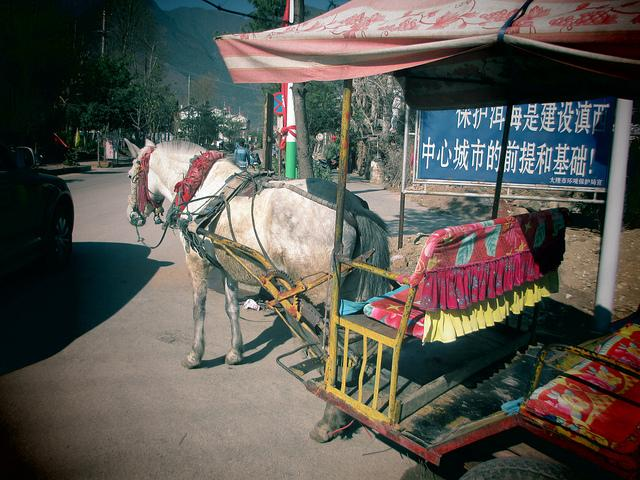
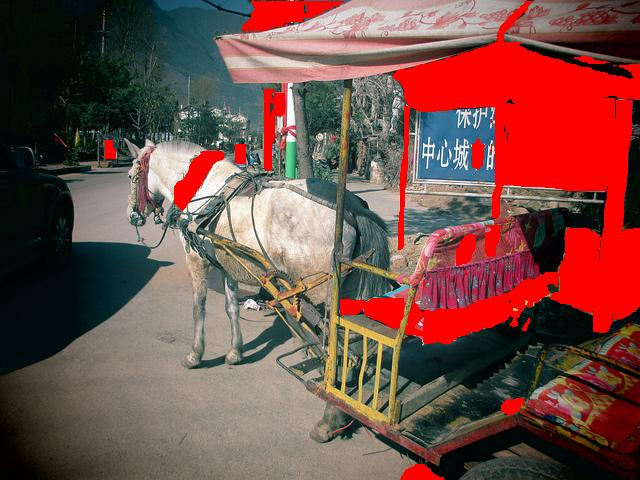
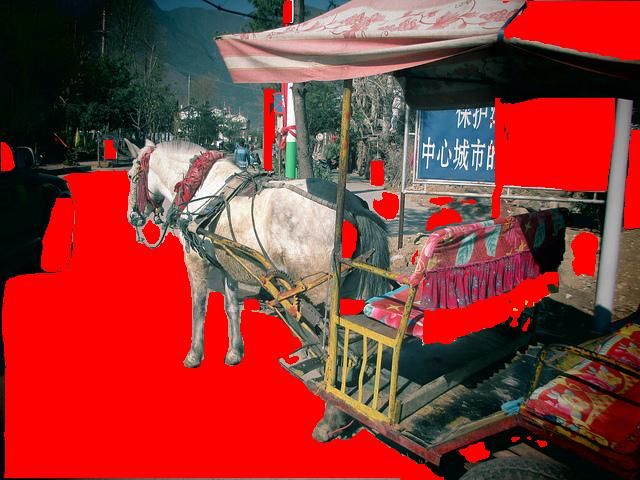

In [30]:
# =============================================================================
# VISUAL CASE STUDY 
# =============================================================================
!pip install -q ultralytics
import os, json, random, requests, io, base64, difflib, torch
import numpy as np
import pandas as pd
from PIL import Image
from ultralytics import FastSAM
from IPython.display import display, HTML

# 1. RECREATE THE EXACT RANDOM STATE FROM YOUR CELL 1
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Download annotations if missing to get the exact sorted list
if not os.path.exists("annotations/captions_val2014.json"):
    print("Downloading COCO annotations to match Cell 1...")
    os.system("wget -q http://images.cocodataset.org/annotations/annotations_trainval2014.zip")
    os.system("unzip -q annotations_trainval2014.zip")

with open("annotations/captions_val2014.json", "r") as f:
    coco_data = json.load(f)

image_id_to_refs = {}
for ann in coco_data["annotations"]:
    img_id = str(ann["image_id"]).zfill(12)
    image_id_to_refs.setdefault(img_id, []).append(ann["caption"])

# THIS IS THE EXACT SHUFFLE FROM YOUR ORIGINAL CELL 1
sampled_image_ids = random.sample(sorted(list(image_id_to_refs.keys())), 500)

# 2. SELECT THE VERY FIRST IMAGE FROM THE EXPERIMENT
# By choosing index 0, the random state perfectly aligns with your original inference run.
image_number = 0
target_img_id = sampled_image_ids[image_number]
sample_id_int = int(target_img_id)

print(f"🎯 Reconstructing EXACT pixel-perfect masks for Image numbger {image_number} of our experiment (COCO ID: {sample_id_int})...")

url = f"http://images.cocodataset.org/val2014/COCO_val2014_{target_img_id}.jpg"
original_img = Image.open(io.BytesIO(requests.get(url).content)).convert("RGB")
img_array = np.array(original_img)

# Run FastSAM
sam_model = FastSAM("/kaggle/working/FastSAM-s.pt")
results = sam_model(original_img, device="cuda" if torch.cuda.is_available() else "cpu", retina_masks=True, verbose=False)
masks = list(results[0].masks) if results[0].masks else []

# 3. THIS IS YOUR EXACT FUNCTION COPIED FROM CELL 1
def apply_percentage_mask(img_array, masks, target_percentage):
    total_pixels = img_array.shape[0] * img_array.shape[1]
    target_pixels = total_pixels * target_percentage
    masked_array = img_array.copy()
    pixels_removed = 0
    random.shuffle(masks) # This shuffle now matches your inference run perfectly
    for mask in masks:
        mask_bool = mask.data[0].cpu().numpy().astype(bool)
        mask_area = mask_bool.sum()
        if pixels_removed + mask_area <= target_pixels * 1.1:
            masked_array[mask_bool] = [255, 0, 0] # EXACT BLACK USED IN CELL 1
            pixels_removed += mask_area
        if pixels_removed >= target_pixels:
            break
    return Image.fromarray(masked_array)

img_15 = apply_percentage_mask(img_array, masks, 0.15) if masks else original_img
img_30 = apply_percentage_mask(img_array, masks, 0.30) if masks else original_img

# 4. HTML Helpers
def img_html(img):
    b = io.BytesIO()
    img.save(b, format="JPEG")
    return f'<img src="data:image/jpeg;base64,{base64.b64encode(b.getvalue()).decode("utf-8")}" width="100%" style="border: 2px solid white; box-shadow: 2px 2px 5px rgba(0,0,0,0.3); max-width: 250px;">'

def high_diff(t1, t2):
    w1, w2 = str(t1).split(), str(t2).split()
    m = difflib.SequenceMatcher(None, w1, w2)
    return " ".join([" ".join(w2[j1:j2]) if tag == 'equal' else f'<span style="color: #d95f02; font-weight: bold;">{" ".join(w2[j1:j2])}</span>' for tag, i1, i2, j1, j2 in m.get_opcodes()]).strip()

# 5. Build Layout
df = pd.read_csv("/kaggle/working/combined_evaluation_dataset.csv")

html = f"""
<div style="background: #eaeaea; padding: 20px; font-family: Arial; border-radius: 10px;">
    <h2 style="text-align: center; margin-top:0;">COCO ID: {sample_id_int}</h2>

    <!-- TOP ROW: THE 3 IMAGES -->
    <div style="display: flex; justify-content: center; gap: 20px; margin-bottom: 30px;">
        <div style="text-align: center;">
            {img_html(original_img)} <div style="font-weight:bold; margin-top:5px;">Original Image</div>
        </div>
        <div style="text-align: center;">
            {img_html(img_15)} <div style="font-weight:bold; margin-top:5px;">15% Mask (Red)</div>
        </div>
        <div style="text-align: center;">
            {img_html(img_30)} <div style="font-weight:bold; margin-top:5px;">30% Mask (Red)</div>
        </div>
    </div>
"""

# BOTTOM ROWS: THE 4 TEXT COMPARISONS
for m in ["LLaVA-1.5-7B", "Qwen2.5-VL-3B", "Qwen2-VL-7B"]:
    row = df[(df['image_id'] == sample_id_int) & (df['model'] == m)].iloc[0]
    
    t_base = row['base_0']
    t_g0 = row['ground_0']
    t_g15 = row['ground_15']
    t_g30 = row['ground_30']
    
    html += f"""
        <div style="background: white; padding: 15px; border-radius: 8px; box-shadow: 1px 1px 4px rgba(0,0,0,0.2); margin-bottom: 20px;">
            <h3 style="margin: 0 0 10px 0; border-bottom: 2px solid #ccc;">{m}</h3>
            
            <div style="display: flex; gap: 15px;">
                <div style="flex: 1;">
                    <b>Base (0%):</b><br><span style="font-size: 11px; color: #555;">Original Prompt</span>
                    <div style="background: #f8f9fa; border: 1px solid #ccc; border-radius: 8px; padding: 10px; margin-top: 5px; font-size: 13px; height: 100%;">{t_base}</div>
                </div>
                <div style="flex: 1;">
                    <b>Ground (0%):</b><br><span style="font-size: 11px; color: #555;">Grounded Prompt + Original Img</span>
                    <div style="background: #e6f2ff; border: 1px solid #000; border-radius: 8px; padding: 10px; margin-top: 5px; font-size: 13px; height: 100%;">{high_diff(t_base, t_g0)}</div>
                </div>
                <div style="flex: 1;">
                    <b>Ground (15%):</b><br><span style="font-size: 11px; color: #555;">Grounded Prompt + 15% Mask</span>
                    <div style="background: #e6f2ff; border: 1px solid #000; border-radius: 8px; padding: 10px; margin-top: 5px; font-size: 13px; height: 100%;">{high_diff(t_base, t_g15)}</div>
                </div>
                <div style="flex: 1;">
                    <b>Ground (30%):</b><br><span style="font-size: 11px; color: #555;">Grounded Prompt + 30% Mask</span>
                    <div style="background: #e6f2ff; border: 1px solid #000; border-radius: 8px; padding: 10px; margin-top: 5px; font-size: 13px; height: 100%;">{high_diff(t_base, t_g30)}</div>
                </div>
            </div>
        </div>
    """

display(HTML(html + "</div>"))